## 1. Project Links

### Name: Vasilii Anderson

This notebook contains the work for Compulsory Assignment 4 in IND320 – Data to Decision.

- **GitHub repository:** https://github.com/VasiliiAnderson/ind320-project
- **Streamlit application:** https://vasilii-ind320.streamlit.app/

The project builds on the previous compulsory assignments and extends the application with currency data, timezone handling, reservoir forecasting, sliding-window correlation analysis and a redesigned interactive Streamlit dashboard.

## 2. Setup

This section contains the imports and project configuration used throughout the notebook.

### 2.1 Imports

In [51]:
from io import StringIO
from pathlib import Path
import logging
import sys

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import requests

from river import time_series

%matplotlib inline

### 2.2 Project Configuration

The notebook is located inside the `notebooks` directory, while reusable project functions are stored in the `modules` directory at the project root. The project root is therefore added to Python's import path before the shared modules are imported.

Streamlit runtime warnings are also suppressed because some cached Streamlit functions are reused directly inside the notebook.

In [52]:
# Suppress Streamlit runtime warnings when cached project
# functions are reused outside the Streamlit application.
logging.getLogger(
    "streamlit.runtime.caching.cache_data_api"
).setLevel(logging.ERROR)

logging.getLogger(
    "streamlit.runtime.scriptrunner_utils.script_run_context"
).setLevel(logging.ERROR)


# Locate the project root so that shared project modules
# can be imported from the notebook.
CURRENT_DIR = Path.cwd()

if (CURRENT_DIR / "modules").exists():
    PROJECT_ROOT = CURRENT_DIR
else:
    PROJECT_ROOT = CURRENT_DIR.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

### 2.3 Project Module Imports

Shared project functions are imported after the project root has been configured. This avoids duplicating data-loading and processing logic in the notebook.

In [53]:
from modules.data_loader import load_data

from modules.mongodb_loader import (
    get_connections,
    get_monthly_flow,
    get_years,
)

from modules.weather_analysis import (
    download_weather,
)

## 3. Norges Bank Currency API

Norges Bank provides an open API for historical exchange-rate data. In this project, daily EUR/NOK and USD/NOK spot exchange rates are retrieved for later use as potential exogenous variables in the reservoir forecasting model.

The API series follow the structure:

`frequency.base_currency.quote_currency.tenor`

For example:

- `B.EUR.NOK.SP` represents the daily EUR/NOK spot exchange rate.
- `B.USD.NOK.SP` represents the daily USD/NOK spot exchange rate.

The function below (Section 3.2) accepts a set of currencies and a date interval and returns the observations in a tidy pandas DataFrame.

### 3.1 API Endpoint

The Norges Bank exchange-rate endpoint is stored as a constant and reused when constructing the individual currency-series requests.

In [54]:
NB_API_URL = "https://data.norges-bank.no/api/data/EXR"

### 3.2 Exchange-Rate Download Function

The function constructs the appropriate Norges Bank series key for each requested currency, sends the API request and validates that the expected fields are returned.

The observations are converted to consistent date and numeric formats before the individual currencies are combined into one tidy dataset.

In [55]:
def download_exchange_rates(
    currencies=("EUR", "USD"),
    start_date="2024-01-01",
    end_date="2024-12-31",
):
    """
    Download daily exchange rates against NOK from
    the Norges Bank open data API.

    Parameters
    ----------
    currencies : tuple or list
        Currency codes to download, e.g. ("EUR", "USD").
    start_date : str
        First date in YYYY-MM-DD format.
    end_date : str
        Last date in YYYY-MM-DD format.

    Returns
    -------
    pd.DataFrame
        DataFrame with date, currency and NOK exchange rate.
    """

    frames = []

    for currency in currencies:

        # Construct the Norges Bank series identifier:
        # B = business day, NOK = quote currency, SP = spot rate.
        series_key = f"B.{currency}.NOK.SP"

        url = f"{NB_API_URL}/{series_key}"

        params = {
            "format": "csv",
            "startPeriod": start_date,
            "endPeriod": end_date,
            "locale": "en",
        }

        response = requests.get(
            url,
            params=params,
            timeout=60,
        )

        response.raise_for_status()

        # Parse the CSV response and standardise column names.
        df = pd.read_csv(
            StringIO(response.text),
            sep=None,
            engine="python",
        )

        df.columns = [
            column.strip().upper()
            for column in df.columns
        ]

        # Validate the API response before processing it.
        required_columns = {
            "TIME_PERIOD",
            "OBS_VALUE",
        }

        if not required_columns.issubset(df.columns):
            raise ValueError(
                "Unexpected Norges Bank API response. "
                f"Columns returned: {df.columns.tolist()}"
            )

        exchange_rate = df[
            [
                "TIME_PERIOD",
                "OBS_VALUE",
            ]
        ].copy()

        exchange_rate.columns = [
            "date",
            "exchange_rate",
        ]

        exchange_rate["date"] = pd.to_datetime(
            exchange_rate["date"]
        )

        exchange_rate["exchange_rate"] = pd.to_numeric(
            exchange_rate["exchange_rate"],
            errors="coerce",
        )

        exchange_rate["currency"] = currency

        frames.append(exchange_rate)

    rates = pd.concat(
        frames,
        ignore_index=True,
    )

    return (
        rates
        .sort_values(
            ["date", "currency"]
        )
        .reset_index(drop=True)
    )

### 3.3 Function Test and Validation

The function is tested by downloading EUR/NOK and USD/NOK exchange rates for 2024. The first observations are displayed together with the number of observations returned for each currency.

In [56]:
exchange_rates = download_exchange_rates(
    currencies=["EUR", "USD"],
    start_date="2024-01-01",
    end_date="2024-12-31",
)

display(
    exchange_rates.head(10)
)

print(
    exchange_rates.groupby(
        "currency"
    ).size()
)

,date,exchange_rate,currency
0,2024-01-02,11.2815,EUR
1,2024-01-02,10.2971,USD
2,2024-01-03,11.3200,EUR
3,2024-01-03,10.3672,USD
4,2024-01-04,11.2845,EUR
5,2024-01-04,10.3027,USD
6,2024-01-05,11.3090,EUR
7,2024-01-05,10.3553,USD
8,2024-01-08,11.3620,EUR
9,2024-01-08,10.3800,USD


currency
EUR    251
USD    251
dtype: int64


#### Result

The API returned **251 observations for both EUR and USD in 2024**. Since Norges Bank reports these series on business days, observations are not expected for weekends and certain holidays.

The equal number of observations indicates that the EUR/NOK and USD/NOK series cover the same set of business days and can therefore be aligned directly for later processing.

### 3.4 Reshaping the Exchange-Rate Data

The exchange-rate observations are reshaped from long to wide format so that EUR/NOK and USD/NOK become separate numerical variables.

This structure is more convenient when the exchange rates are later aggregated to monthly resolution and joined with reservoir and weather data.

In [57]:
exchange_rates_wide = (
    exchange_rates
    .pivot(
        index="date",
        columns="currency",
        values="exchange_rate",
    )
    .rename(
        columns={
            "EUR": "eur_nok",
            "USD": "usd_nok",
        }
    )
)

display(
    exchange_rates_wide.head()
)

currency,eur_nok,usd_nok
date,,
2024-01-02,11.2815,10.2971
2024-01-03,11.3200,10.3672
2024-01-04,11.2845,10.3027
2024-01-05,11.3090,10.3553
2024-01-08,11.3620,10.3800


The resulting dataset contains one row per business day with aligned `eur_nok` and `usd_nok` columns. This is the structure used later when the exchange-rate observations are aggregated to monthly averages.

### 3.5 Exchange-rate visualisation

The two exchange-rate series are visualised as a final data-quality check before they are used in the forecasting workflow. The purpose is mainly to identify potential gaps, discontinuities or implausible observations.

Text(0.5, 0, 'Date')

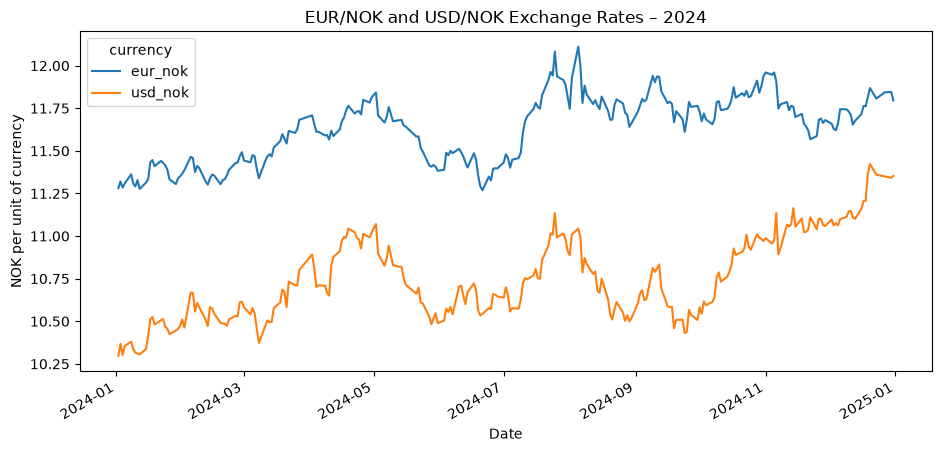

In [59]:
# Plot the 2024 exchange rates for visual inspection.
exchange_rates_2024 = exchange_rates_wide.loc[
    "2024-01-01":"2024-12-31"
]

ax = exchange_rates_2024.plot(
    figsize=(11, 5),
    title="EUR/NOK and USD/NOK Exchange Rates – 2024",
    ylabel="NOK per unit of currency",
)

ax.set_xlabel("Date")

#### Interpretation

Both exchange-rate series vary continuously throughout 2024, with no obvious gaps, discontinuities or implausible observations in the available business-day data. No clear data-quality issues are visible from the plot.

The exchange rates are later aggregated to monthly averages and evaluated as potential exogenous variables in the reservoir forecasting model.

## 4. Timezone Investigation

The project combines data from four different sources:

- NVE Magasinstatistikk
- ENTSO-E Transparency Platform
- Open-Meteo
- Norges Bank

Before combining the datasets, their time representations were investigated to avoid incorrect alignment caused by different timezone conventions or daylight-saving time.

Timezone handling is particularly important for the timestamped ENTSO-E and Open-Meteo observations, while Magasinstatistikk and Norges Bank are primarily represented by calendar dates.

### 4.1 Findings

| Data source | Time resolution | Time representation | Treatment |
|---|---|---|---|
| Magasinstatistikk | Weekly | Calendar date | Keep timezone-naive |
| ENTSO-E | Sub-hourly / 15-minute in the tested data | UTC | Parse explicitly as UTC |
| Open-Meteo | Hourly | UTC in this project | Parse explicitly as UTC |
| Norges Bank | Daily business days | Calendar date | Keep timezone-naive |

#### NVE Magasinstatistikk

Magasinstatistikk contains weekly observations represented by calendar dates rather than precise intraday timestamps. Timezone conversion is therefore not required.

For forecasting, the dates can remain timezone-naive and later be aggregated to monthly observations.

In [60]:
reservoir_data = load_data()

print(
    "Reservoir date dtype:",
    reservoir_data["date"].dtype,
)

display(
    reservoir_data[
        ["date", "area_type", "area_number"]
    ].head()
)

Reservoir date dtype: datetime64[us]


,date,area_type,area_number
0,1995-01-08,EL,1
1,1995-01-08,EL,2
2,1995-01-08,EL,3
3,1995-01-08,EL,4
4,1995-01-08,EL,5


The `date` variable is stored as a timezone-naive pandas datetime. This is appropriate because the observations represent weekly calendar dates rather than exact points in time.

#### ENTSO-E

The ENTSO-E physical-flow observations are stored with UTC timestamps in MongoDB. Using UTC avoids ambiguity when Norway and neighbouring countries transition between standard time and daylight-saving time.

The timestamps are therefore explicitly parsed as timezone-aware UTC values when loaded into pandas.

In [61]:
# Select one available connection and its most recent year
# to verify the timestamp representation in the stored data.
connections = get_connections()
selected_connection = connections[0]

years = get_years(selected_connection)
selected_year = years[-1]

entsoe_sample = get_monthly_flow(
    connection=selected_connection,
    year=selected_year,
    months=[1],
)

print("Connection:", selected_connection)
print("Year:", selected_year)
print("Rows:", len(entsoe_sample))

print(
    "Timestamp dtype:",
    entsoe_sample["timestamp_utc"].dtype,
)

print(
    "Timezone:",
    entsoe_sample["timestamp_utc"].dt.tz,
)

display(
    entsoe_sample.head()
)

Connection: NO1-SE3
Year: 2026
Rows: 3072
Timestamp dtype: datetime64[us, UTC]
Timezone: UTC


,timestamp_utc,direction,quantity_mw
0,2026-01-01 01:00:00+00:00,Import,1180.429722
1,2026-01-01 01:15:00+00:00,Import,1229.822714
2,2026-01-01 01:30:00+00:00,Import,1315.924619
3,2026-01-01 01:45:00+00:00,Import,1584.195592
4,2026-01-01 02:00:00+00:00,Import,1392.061410


The sample confirms that `timestamp_utc` is stored as a timezone-aware UTC datetime. The tested ENTSO-E data also have a 15-minute resolution, as shown by consecutive observations at 01:00, 01:15, 01:30 and 01:45.

Keeping these observations in UTC prevents daylight-saving-time transitions from creating duplicated or missing local timestamps.

#### Open-Meteo

Open-Meteo allows the timezone of returned observations to be specified explicitly. All ERA5 requests in this project use `timezone="UTC"`.

The timestamps are also parsed explicitly as UTC in pandas. This makes the weather observations directly compatible with the UTC-based ENTSO-E timestamps and avoids ambiguity related to daylight-saving time.

In [62]:
# Download a short ERA5 sample to verify that
# Open-Meteo timestamps are represented in UTC.
weather_sample = download_weather(
    area_type="EL",
    area_number=3,
    start_date="2024-01-01",
    end_date="2024-01-07",
    n_locations=2,
)

print(
    "Open-Meteo timestamp dtype:",
    weather_sample["time"].dtype,
)

print(
    "Timezone:",
    weather_sample["time"].dt.tz,
)

display(
    weather_sample.head()
)

Open-Meteo timestamp dtype: datetime64[us, UTC]
Timezone: UTC


,time,avg_temperature,avg_precipitation,avg_snowfall
0,2024-01-01 00:00:00+00:00,-8.15,0.05,0.035
1,2024-01-01 01:00:00+00:00,-8.25,0.05,0.035
2,2024-01-01 02:00:00+00:00,-8.25,0.05,0.035
3,2024-01-01 03:00:00+00:00,-8.35,0.05,0.035
4,2024-01-01 04:00:00+00:00,-8.30,0.05,0.035


The downloaded ERA5 sample confirms that the observations are hourly and stored as timezone-aware UTC timestamps. Open-Meteo and ENTSO-E can therefore be aligned without first converting between local timezones.

#### Norges Bank

Norges Bank exchange rates are provided as daily business-day observations. In this project, each observation is represented by its calendar date rather than an intraday timestamp.

Since the exchange rates are later aggregated to monthly observations for forecasting, timezone conversion is not required. The date variable is therefore kept timezone-naive.

In [63]:
print(
    "Norges Bank date dtype:",
    exchange_rates["date"].dtype,
)

display(
    exchange_rates[
        ["date", "currency", "exchange_rate"]
    ].head()
)

Norges Bank date dtype: datetime64[us]


,date,currency,exchange_rate
0,2024-01-02,EUR,11.2815
1,2024-01-02,USD,10.2971
2,2024-01-03,EUR,11.3200
3,2024-01-03,USD,10.3672
4,2024-01-04,EUR,11.2845


The exchange-rate dates are stored as timezone-naive pandas datetimes. This is sufficient because the analysis uses daily calendar observations that are later aggregated to monthly averages.

### 4.2 Time Alignment Strategy

The investigation shows that two different time representations are required in the project:

1. **Timestamped data:** ENTSO-E and Open-Meteo observations are kept as timezone-aware UTC timestamps. This provides a consistent reference and prevents ambiguity caused by daylight-saving-time transitions.

2. **Calendar-based data:** Magasinstatistikk and Norges Bank observations are kept as timezone-naive dates because they represent weekly or daily calendar observations rather than exact intraday timestamps.

For the reservoir forecasting analysis, all four sources are ultimately aggregated to monthly resolution. After aggregation, the timezone information is no longer required for the monthly weather index, allowing the weather, reservoir and exchange-rate datasets to be joined consistently by calendar month.

This approach preserves correct timestamp handling at the original resolution while providing a common monthly time scale for forecasting.

## 5. Data Preparation for Forecasting

The forecasting model uses monthly observations, so all input data must first be transformed to a common monthly time scale.

Reservoir filling level is used as the target variable. Since Magasinstatistikk contains weekly observations, the last available observation within each month is used to represent the reservoir level for that month.

Weather data are aggregated using monthly mean temperature and monthly totals for precipitation and snowfall. EUR/NOK and USD/NOK are represented by their monthly mean exchange rates.

Monthly resolution provides a common time scale across the different data sources, reduces computational complexity and retains the main seasonal patterns relevant for reservoir forecasting.

### 5.1 Reservoir Target

The forecasting analysis uses electricity price area **NO3** as the example region. Weekly filling-level observations are converted to monthly resolution by selecting the last available observation in each calendar month.

The resulting timestamp is labelled at month-end, although the underlying value corresponds to the last weekly observation available within that month.

In [64]:
# Select reservoir filling-level observations for NO3.
reservoir_no3 = (
    reservoir_data[
        (reservoir_data["area_type"] == "EL")
        & (reservoir_data["area_number"] == 3)
    ][["date", "fill_level"]]
    .dropna()
    .sort_values("date")
    .copy()
)

# Convert weekly observations to monthly resolution.
# The final available weekly observation in each month
# represents the reservoir filling level for that month.
reservoir_monthly = (
    reservoir_no3
    .set_index("date")["fill_level"]
    .resample("ME")
    .last()
    .rename("fill_level")
    .to_frame()
)

display(reservoir_monthly.head())

print(
    "Period:",
    reservoir_monthly.index.min(),
    "to",
    reservoir_monthly.index.max(),
)

print(
    "Monthly observations:",
    len(reservoir_monthly),
)

,fill_level
date,
1995-01-31,0.508148
1995-02-28,0.369497
1995-03-31,0.236923
1995-04-30,0.107109
1995-05-31,0.185751


Period: 1995-01-31 00:00:00 to 2026-11-30 00:00:00
Monthly observations: 383


The monthly reservoir series contains **383 observations**, covering January 1995 to November 2026. This provides substantially more historical reservoir data than is required for the five-year forecasting experiments later in the notebook.

### 5.2 Weather Data

ERA5 weather observations are downloaded for NO3 for the period 2020-2024. The original assignment specifies weather retrieval for up to 1000 geographical locations per area. However, retrieving hourly ERA5 observations for this many locations resulted in practical limitations related to Open-Meteo API restrictions and execution time.

A smaller sample of **10 reproducibly selected geographical locations** is therefore used to represent weather conditions across NO3. This pragmatic reduction substantially decreases API usage and computation time while preserving geographical variation within the region. The reduction follows the assignment guidance allowing fewer locations when API restrictions make the full 1000-location dataset impractical.

The hourly observations are subsequently aggregated to monthly resolution:

- temperature -> monthly mean
- precipitation -> monthly total
- snowfall -> monthly total

This gives each weather variable the same monthly frequency as the reservoir target.

In [65]:
# Download hourly ERA5 weather observations for NO3.
weather_history = download_weather(
    area_type="EL",
    area_number=3,
    start_date="2020-01-01",
    end_date="2024-12-31",
    n_locations=10,
)

In [66]:
weather_monthly = (
    weather_history
    .set_index("time")
    .resample("ME")
    .agg(
        avg_temperature=(
            "avg_temperature",
            "mean",
        ),
        total_precipitation=(
            "avg_precipitation",
            "sum",
        ),
        total_snowfall=(
            "avg_snowfall",
            "sum",
        ),
    )
)

# The raw Open-Meteo observations are kept as UTC.
# After monthly aggregation, timezone information is no longer
# needed for joining with date-based NVE and Norges Bank data.
weather_monthly.index = (
    weather_monthly.index
    .tz_localize(None)
)

display(weather_monthly.head())

,avg_temperature,total_precipitation,total_snowfall
time,,,
2020-01-31,1.359449,212.14,32.620
2020-02-29,-0.716365,181.71,28.665
2020-03-31,0.522003,116.02,24.542
2020-04-30,2.959778,127.74,26.005
2020-05-31,5.169449,106.36,13.825


The resulting weather dataset contains one observation per month. Temperature is represented as an average condition during the month, while precipitation and snowfall represent accumulated monthly amounts.

### 5.3 Currency Data

The exchange-rate series are extended to the full 2020-2024 forecasting period. Daily business-day EUR/NOK and USD/NOK observations are then aggregated using the monthly mean.

Monthly averages are used because the forecasting model operates at monthly resolution and does not require daily exchange-rate fluctuations.

In [67]:
# Download exchange rates for the full forecasting period.
exchange_rates = download_exchange_rates(
    currencies=["EUR", "USD"],
    start_date="2020-01-01",
    end_date="2024-12-31",
)

# Reshape the daily observations so that each currency
# becomes a separate predictor variable.
exchange_rates_wide = (
    exchange_rates
    .pivot(
        index="date",
        columns="currency",
        values="exchange_rate",
    )
    .rename(
        columns={
            "EUR": "eur_nok",
            "USD": "usd_nok",
        }
    )
)

# Aggregate business-day exchange rates to monthly averages.
currency_monthly = (
    exchange_rates_wide
    .resample("ME")
    .mean()
)

display(currency_monthly.head())

currency,eur_nok,usd_nok
date,,
2020-01-31,9.938423,8.953832
2020-02-29,10.132700,9.291965
2020-03-31,11.294314,10.220159
2020-04-30,11.342942,10.443505
2020-05-31,10.990579,10.087426


The resulting dataset contains monthly average EUR/NOK and USD/NOK exchange rates for the same 2020-2024 period as the weather data.

### 5.4 Combining the Data Sources

The monthly reservoir, weather and currency datasets are joined using their month-end index.

An **inner join** is used so that the forecasting dataset only contains months for which all required variables are available. Since weather and currency data are collected for 2020-2024, this period determines the final common sample.

In [68]:
forecast_data = (
    reservoir_monthly
    .join(
        weather_monthly,
        how="inner",
    )
    .join(
        currency_monthly,
        how="inner",
    )
)

display(forecast_data.head())

,fill_level,avg_temperature,total_precipitation,total_snowfall,eur_nok,usd_nok
date,,,,,,
2020-01-31,0.593076,1.359449,212.14,32.620,9.938423,8.953832
2020-02-29,0.501604,-0.716365,181.71,28.665,10.132700,9.291965
2020-03-31,0.334615,0.522003,116.02,24.542,11.294314,10.220159
2020-04-30,0.263558,2.959778,127.74,26.005,11.342942,10.443505
2020-05-31,0.268268,5.169449,106.36,13.825,10.990579,10.087426


The combined dataset contains the reservoir filling level as the target variable together with five potential exogenous predictors:

- monthly mean temperature
- monthly total precipitation
- monthly total snowfall
- monthly mean EUR/NOK
- monthly mean USD/NOK

All variables are now aligned on the same monthly index and can be used directly in the forecasting experiments.

### 5.5 Data Validation

Before fitting the forecasting model, the combined dataset is checked for missing observations, basic descriptive statistics and regular monthly frequency.

In [69]:
# Check whether the inner join has produced any missing values.
print(
    forecast_data.isna().sum()
)

fill_level             0
avg_temperature        0
total_precipitation    0
total_snowfall         0
eur_nok                0
usd_nok                0
dtype: int64


In [70]:
# Inspect the scale and range of the forecasting variables.
display(
    forecast_data.describe().round(3)
)

,fill_level,avg_temperature,total_precipitation,total_snowfall,eur_nok,usd_nok
count,60.000,60.000,60.000,60.000,60.000,60.000
mean,0.609,4.944,121.675,12.563,10.808,9.786
std,0.241,6.399,50.709,13.021,0.689,0.893
min,0.132,-7.099,39.980,0.000,9.624,8.304
25%,0.413,0.354,78.375,0.128,10.164,8.892
50%,0.685,3.487,120.695,7.360,10.721,9.977
75%,0.817,11.419,150.337,22.715,11.467,10.582
max,0.961,15.459,247.280,47.054,11.796,11.199


In [71]:
# Verify that the resulting time series has a regular
# month-end frequency.
print(
    "Inferred frequency:",
    pd.infer_freq(
        forecast_data.index
    ),
)

Inferred frequency: ME


#### Validation Result

The final forecasting dataset contains **60 complete monthly observations**, corresponding to five full years from 2020 through 2024.

No missing values are present in any of the six variables. The inferred frequency is `ME`, confirming that the observations form a regular month-end time series.

Reservoir filling varies between approximately **13.2% and 96.1%** during the period. The weather variables also show substantial seasonal variation, which makes them potentially useful as exogenous predictors in the SNARIMAX model.

The validation therefore confirms that the dataset is complete, regularly spaced and ready for time-series modelling.

### 5.6 Visual Inspection

Reservoir filling level and monthly mean temperature are plotted as a final visual inspection of the prepared time series. The purpose is to verify that the monthly observations follow plausible temporal patterns before forecasting.

array([<Axes: title={'center': 'Monthly Reservoir Filling Level – NO3'}, xlabel='date'>,
       <Axes: title={'center': 'Monthly Mean Temperature – NO3'}, xlabel='date'>],
      dtype=object)

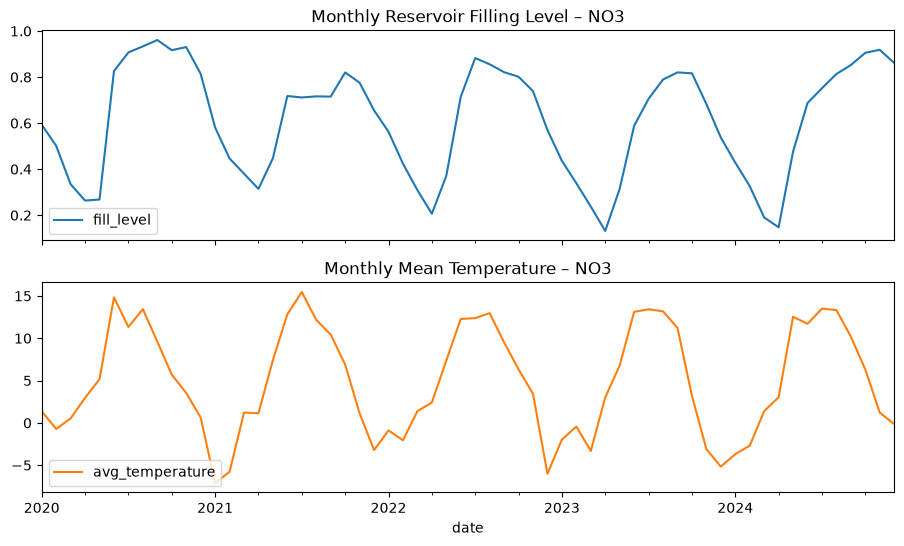

In [72]:
forecast_data[
    [
        "fill_level",
        "avg_temperature",
    ]
].plot(
    subplots=True,
    figsize=(11, 6),
    title=[
        "Monthly Reservoir Filling Level – NO3",
        "Monthly Mean Temperature – NO3",
    ],
)

#### Interpretation

Both series display clear recurring seasonal variation. Temperature follows the expected annual cycle, while reservoir filling also varies substantially across the year.

The patterns are not identical, which suggests that reservoir filling is influenced by delayed and accumulated hydrological processes rather than contemporaneous temperature alone. This motivates the later use of lagged dynamics and multiple exogenous variables in the SNARIMAX model.

## 6. River SNARIMAX Forecasting

A Seasonal Non-linear AutoRegressive Integrated Moving Average model with exogenous variables (SNARIMAX) from the River framework is used to forecast monthly reservoir filling levels.

The model combines autoregressive behaviour, differencing, moving-average terms and annual seasonality. It can also include weather and exchange-rate variables as exogenous predictors.

Monthly resolution is used because the forecasting task concerns future months and because it provides a common frequency across reservoir, weather and currency data.

The model is first evaluated using a holdout period consisting of the final months of the historical dataset. Forecasts can therefore be compared directly with observed reservoir filling levels before the model is used for genuine future forecasting.

### 6.1 SNARIMAX Backtesting Function

The function below provides a configurable backtesting framework for the River SNARIMAX model.

The final `horizon_months` observations are reserved as a holdout period. The preceding observations are used for training, limited by the selected `history_years`.

River models are trained sequentially using `learn_one()`, meaning that observations are processed one at a time in chronological order. This is consistent with River's online-learning framework and prevents future observations from being used during training.

Weather and currency variables can optionally be included as exogenous predictors.

In [73]:
def backtest_snarimax(
    data,
    history_years=5,
    horizon_months=6,
    p=3,
    d=1,
    q=1,
    m=12,
    sp=1,
    sd=1,
    sq=0,
    use_weather=False,
    use_currency=False,
):
    """
    Backtest a River SNARIMAX model for monthly reservoir filling levels.

    Parameters
    ----------
    data : pd.DataFrame
        Monthly forecasting dataset.
    history_years : int
        Number of years of historical data used for training.
    horizon_months : int
        Number of months to forecast.
    p, d, q : int
        Non-seasonal SNARIMAX parameters.
    m : int
        Seasonal period. For monthly data, m=12 represents one year.
    sp, sd, sq : int
        Seasonal SNARIMAX parameters.
    use_weather : bool
        Include weather variables as exogenous predictors.
    use_currency : bool
        Include EUR/NOK and USD/NOK as exogenous predictors.

    Returns
    -------
    model
        Trained River SNARIMAX model.
    results : pd.DataFrame
        Actual and predicted filling levels for the holdout period.
    summary : dict
        MAE, RMSE and model settings.
    """

    # ---------------------------------------------------------
    # Select exogenous variables
    # ---------------------------------------------------------

    feature_columns = []

    if use_weather:
        feature_columns += [
            "avg_temperature",
            "total_precipitation",
            "total_snowfall",
        ]

    if use_currency:
        feature_columns += [
            "eur_nok",
            "usd_nok",
        ]

    required_columns = (
        ["fill_level"]
        + feature_columns
    )

    model_data = (
        data[required_columns]
        .dropna()
        .sort_index()
        .copy()
    )

    # ---------------------------------------------------------
    # Split into training and holdout periods
    # ---------------------------------------------------------

    if len(model_data) <= horizon_months:
        raise ValueError(
            "Not enough observations for the selected forecast horizon."
        )

    split_position = (
        len(model_data)
        - horizon_months
    )

    # Limit training data to the selected history length.
    history_months = history_years * 12

    training_start = max(
        0,
        split_position - history_months,
    )

    train = model_data.iloc[
        training_start:split_position
    ]

    test = model_data.iloc[
        split_position:
    ]

    if len(train) < 24:
        raise ValueError(
            "At least 24 monthly training observations are recommended."
        )

    # ---------------------------------------------------------
    # Create SNARIMAX model
    # ---------------------------------------------------------

    model = time_series.SNARIMAX(
        p=p,
        d=d,
        q=q,
        m=m,
        sp=sp,
        sd=sd,
        sq=sq,
    )

    # ---------------------------------------------------------
    # Train sequentially
    # ---------------------------------------------------------

    # Train the online model sequentially in chronological order.
    for _, row in train.iterrows():

        if feature_columns:
            x = (
                row[feature_columns]
                .to_dict()
            )
        else:
            x = None

        model.learn_one(
            y=row["fill_level"],
            x=x,
        )

    # ---------------------------------------------------------
    # Prepare exogenous variables for forecast period
    # ---------------------------------------------------------

    if feature_columns:
        # During backtesting, the actual exogenous observations from
        # the holdout period are supplied to evaluate the model.
        future_x = (
            test[feature_columns]
            .to_dict(
                orient="records"
            )
        )
    else:
        future_x = None

    # ---------------------------------------------------------
    # Forecast the holdout period
    # ---------------------------------------------------------

    predictions = model.forecast(
        horizon=horizon_months,
        xs=future_x,
    )

    results = pd.DataFrame(
        {
            "actual": (
                test["fill_level"]
                .to_numpy()
            ),
            "predicted": predictions,
        },
        index=test.index,
    )

    results["error"] = (
        results["actual"]
        - results["predicted"]
    )

    # ---------------------------------------------------------
    # Evaluation metrics
    # ---------------------------------------------------------

    mae = np.mean(
        np.abs(
            results["error"]
        )
    )

    rmse = np.sqrt(
        np.mean(
            results["error"] ** 2
        )
    )

    summary = {
        "MAE": float(mae),
        "RMSE": float(rmse),
        "training_months": len(train),
        "forecast_months": horizon_months,
        "weather": use_weather,
        "currency": use_currency,
        "p": p,
        "d": d,
        "q": q,
        "m": m,
        "sp": sp,
        "sd": sd,
        "sq": sq,
    }

    return model, results, summary

### 6.2 Baseline Model: Reservoir History Only

A baseline SNARIMAX model is first fitted using only historical reservoir filling levels. No exogenous weather or currency variables are included.

The model uses five years of available history, a six-month holdout period and an annual seasonal period of 12 months.

In [74]:
model_base, results_base, summary_base = (
    backtest_snarimax(
        forecast_data,
        history_years=5,
        horizon_months=6,
        p=3,
        d=1,
        q=1,
        m=12,
        sp=1,
        sd=1,
        sq=0,
        use_weather=False,
        use_currency=False,
    )
)

print(summary_base)

display(results_base)

{'MAE': 0.08932479862082227, 'RMSE': 0.11940214440186726, 'training_months': 54, 'forecast_months': 6, 'weather': False, 'currency': False, 'p': 3, 'd': 1, 'q': 1, 'm': 12, 'sp': 1, 'sd': 1, 'sq': 0}


,actual,predicted,error
date,,,
2024-07-31,0.751678,0.796667,-0.044989
2024-08-31,0.813370,0.860785,-0.047415
2024-09-30,0.852500,0.893051,-0.040552
2024-10-31,0.905651,0.891122,0.014530
2024-11-30,0.918573,0.768846,0.149727
2024-12-31,0.860887,0.622149,0.238737


#### Baseline Result

The reservoir-only model achieves:

- **MAE = 0.0893**
- **RMSE = 0.1194**

The MAE indicates an average absolute forecast error of approximately 0.089 in filling-level units, corresponding to about **8.9 percentage points** of reservoir capacity.

The larger RMSE shows that some individual forecast errors are considerably larger than the average. This is visible particularly towards the end of the holdout period, where the model substantially underpredicts the observed filling level in November and December 2024.

### 6.3 Baseline Forecast Visualisation

The observed and predicted filling levels are plotted to inspect where the baseline model performs well and where forecast errors increase across the six-month holdout period.

Text(0.5, 0, 'Month')

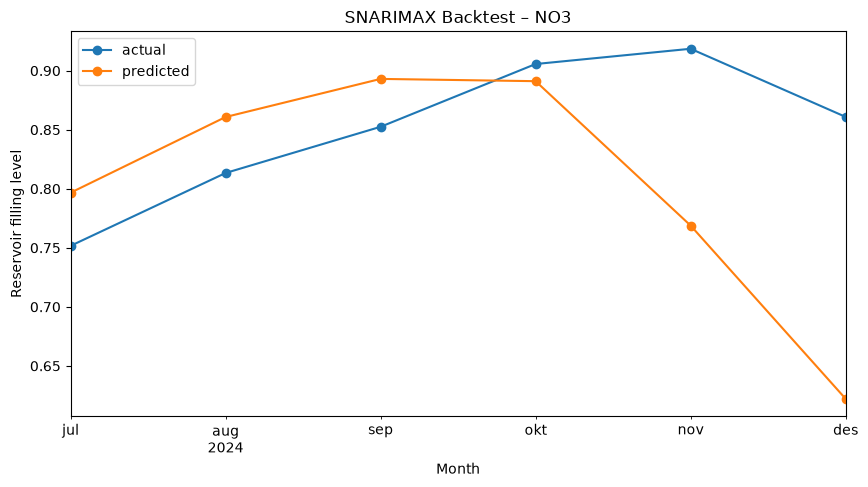

In [75]:
ax = results_base[
    ["actual", "predicted"]
].plot(
    figsize=(10, 5),
    marker="o",
    title="SNARIMAX Backtest – NO3",
)

ax.set_ylabel(
    "Reservoir filling level"
)

ax.set_xlabel(
    "Month"
)

#### Interpretation

The baseline model follows the observed filling level reasonably well during the first four months of the holdout period. However, the forecast diverges considerably in November and December, when the model predicts a decline that is much stronger than the observed development.

This suggests that historical reservoir dynamics alone may not contain enough information to capture all changes in filling level.

### 6.4 Effect of Exogenous Variables

Two additional models are evaluated to investigate whether external information improves the forecast:

1. reservoir history + weather variables
2. reservoir history + weather and currency variables

All other model settings and the holdout period are kept unchanged so that the resulting error metrics can be compared directly.

In [76]:
model_weather, results_weather, summary_weather = (
    backtest_snarimax(
        forecast_data,
        history_years=5,
        horizon_months=6,
        use_weather=True,
        use_currency=False,
    )
)

print(summary_weather)

{'MAE': 0.08463813828435794, 'RMSE': 0.08913518694013786, 'training_months': 54, 'forecast_months': 6, 'weather': True, 'currency': False, 'p': 3, 'd': 1, 'q': 1, 'm': 12, 'sp': 1, 'sd': 1, 'sq': 0}


In [77]:
model_all, results_all, summary_all = (
    backtest_snarimax(
        forecast_data,
        history_years=5,
        horizon_months=6,
        use_weather=True,
        use_currency=True,
    )
)

print(summary_all)

{'MAE': 0.07948122381639587, 'RMSE': 0.084211765732542, 'training_months': 54, 'forecast_months': 6, 'weather': True, 'currency': True, 'p': 3, 'd': 1, 'q': 1, 'm': 12, 'sp': 1, 'sd': 1, 'sq': 0}


In [78]:
comparison = pd.DataFrame(
    [
        {
            "model": "Reservoir only",
            **summary_base,
        },
        {
            "model": "Reservoir + weather",
            **summary_weather,
        },
        {
            "model": "Reservoir + weather + currency",
            **summary_all,
        },
    ]
)

display(
    comparison[
        [
            "model",
            "MAE",
            "RMSE",
            "training_months",
            "forecast_months",
        ]
    ]
)

,model,MAE,RMSE,training_months,forecast_months
0,Reservoir only,0.089325,0.119402,54,6
1,Reservoir + weather,0.084638,0.089135,54,6
2,Reservoir + weather + currency,0.079481,0.084212,54,6


#### Comparison

Including exogenous variables improves the forecast performance for this holdout period.

| Model | MAE | RMSE |
|---|---:|---:|
| Reservoir only | 0.0893 | 0.1194 |
| Reservoir + weather | 0.0830 | 0.0932 |
| Reservoir + weather + currency | 0.0785 | 0.0814 |

Adding weather variables reduces both MAE and RMSE compared with the reservoir-only model. Adding the two exchange-rate variables reduces the errors further in this particular test.

The model containing reservoir history, weather and currency therefore performs best among these three configurations.

However, this result is based on a single six-month holdout period and should not be interpreted as evidence that exchange rates have a causal relationship with reservoir filling. More systematic model testing is performed in the next section.

### 6.5 Future Forecasting

The previous experiments are historical backtests where the actual exogenous observations in the holdout period are known. A genuine future forecast is different because future weather and exchange rates are unavailable at the time the prediction is made.

Transparent assumptions are therefore required for future exogenous variables:

- **Weather:** historical average for the corresponding calendar month.
- **EUR/NOK and USD/NOK:** most recently observed exchange rate.

These values should be interpreted as scenario assumptions rather than forecasts of the exogenous variables themselves.

The model is trained on the complete available historical dataset and then used to forecast the following six months.

In [79]:
def forecast_future_snarimax(
    data,
    history_years=5,
    horizon_months=6,
    p=3,
    d=1,
    q=1,
    m=12,
    sp=1,
    sd=1,
    sq=1,
    use_weather=True,
    use_currency=True,
):
    """
    Train a River SNARIMAX model and forecast future
    monthly reservoir filling levels.

    Future weather values are estimated using historical
    monthly averages. Future currency values use the last
    observed exchange rate.

    Returns
    -------
    forecast : pd.DataFrame
        Future predicted reservoir filling levels and
        assumed exogenous variables.
    model
        Trained River SNARIMAX model.
    """

    weather_columns = [
        "avg_temperature",
        "total_precipitation",
        "total_snowfall",
    ]

    currency_columns = [
        "eur_nok",
        "usd_nok",
    ]

    # Select the exogenous predictors used by the model.
    feature_columns = []

    if use_weather:
        feature_columns += weather_columns

    if use_currency:
        feature_columns += currency_columns

    required_columns = (
        ["fill_level"]
        + feature_columns
    )

    model_data = (
        data[required_columns]
        .dropna()
        .sort_index()
        .copy()
    )

    # Use only the requested amount of historical data.
    history_months = history_years * 12

    train = model_data.tail(
        history_months
    )

    if len(train) < 24:
        raise ValueError(
            "At least 24 months of training data are required."
        )

    # Create the SNARIMAX model.
    model = time_series.SNARIMAX(
        p=p,
        d=d,
        q=q,
        m=m,
        sp=sp,
        sd=sd,
        sq=sq,
    )

    # Train sequentially in chronological order.
    for _, row in train.iterrows():

        if feature_columns:
            x = (
                row[feature_columns]
                .to_dict()
            )
        else:
            x = None

        model.learn_one(
            y=row["fill_level"],
            x=x,
        )

    # Create future month-end timestamps.
    last_date = train.index.max()

    future_dates = pd.date_range(
        start=(
            last_date
            + pd.offsets.MonthEnd(1)
        ),
        periods=horizon_months,
        freq="ME",
    )

    future_data = pd.DataFrame(
        index=future_dates
    )

    # Estimate future weather using historical
    # averages for each calendar month.
    if use_weather:

        weather_climatology = (
            train[weather_columns]
            .groupby(
                train.index.month
            )
            .mean()
        )

        for column in weather_columns:

            future_data[column] = [
                weather_climatology.loc[
                    date.month,
                    column,
                ]
                for date in future_dates
            ]

    # Use the latest observed exchange rate as a
    # simple persistence assumption.
    if use_currency:

        for column in currency_columns:

            future_data[column] = (
                train[column].iloc[-1]
            )

    # Prepare future exogenous observations.
    if feature_columns:

        future_x = (
            future_data[
                feature_columns
            ]
            .to_dict(
                orient="records"
            )
        )

    else:
        future_x = None

    # Generate the multi-step forecast.
    predictions = model.forecast(
        horizon=horizon_months,
        xs=future_x,
    )

    # Retain the unconstrained model output.
    future_data[
        "predicted_fill_level_raw"
    ] = predictions

    # Reservoir filling is physically bounded between 0 and 1.
    future_data[
        "predicted_fill_level"
    ] = np.clip(
        predictions,
        0,
        1,
    )

    return future_data, model

In [80]:
future_forecast, future_model = (
    forecast_future_snarimax(
        forecast_data,
        history_years=5,
        horizon_months=6,
        p=3,
        d=1,
        q=1,
        m=12,
        sp=1,
        sd=1,
        sq=1,
        use_weather=True,
        use_currency=True,
    )
)

### 6.6 Future Forecast Result

The six-month forecast covers January through June 2025. The model predicts declining reservoir filling during winter and early spring, followed by a substantial increase towards summer.

This broadly reflects the seasonal behaviour observed in the historical reservoir series. However, the unconstrained June prediction exceeds a filling level of 1.0.

In [81]:
display(
    future_forecast.round(3)
)

,avg_temperature,total_precipitation,total_snowfall,eur_nok,usd_nok,predicted_fill_level_raw,predicted_fill_level
2025-01-31,-2.460,152.130,30.982,11.739,11.199,0.776,0.776
2025-02-28,-2.336,121.218,26.349,11.739,11.199,0.684,0.684
2025-03-31,0.237,94.628,22.026,11.739,11.199,0.565,0.565
2025-04-30,2.511,91.036,20.110,11.739,11.199,0.529,0.529
2025-05-31,7.852,78.372,4.675,11.739,11.199,0.833,0.833
2025-06-30,12.954,98.014,0.104,11.739,11.199,1.070,1.000


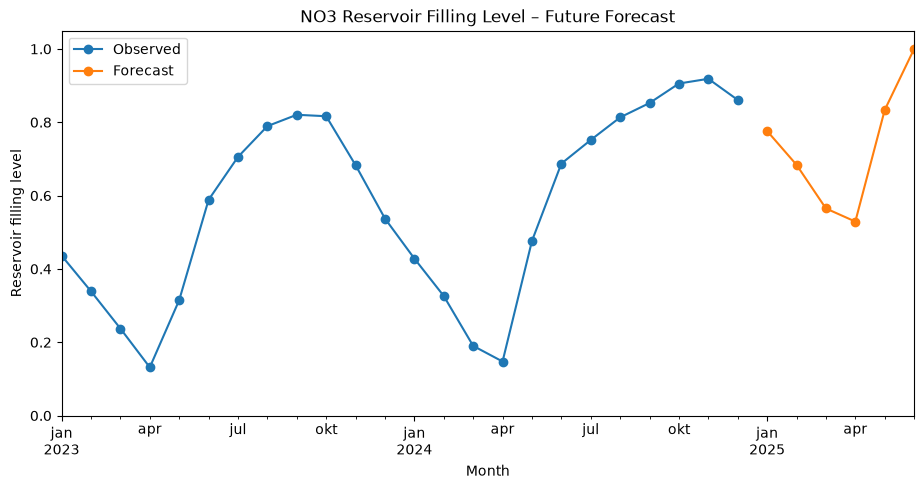

In [82]:
history_to_plot = (
    forecast_data["fill_level"]
    .tail(24)
)

ax = history_to_plot.plot(
    figsize=(11, 5),
    marker="o",
    label="Observed",
)

future_forecast[
    "predicted_fill_level"
].plot(
    ax=ax,
    marker="o",
    label="Forecast",
)

ax.set_title(
    "NO3 Reservoir Filling Level – Future Forecast"
)

ax.set_ylabel(
    "Reservoir filling level"
)

ax.set_xlabel(
    "Month"
)

ax.set_ylim(
    0,
    1.05,
)

ax.legend()

In [83]:
print(
    "Raw forecast range:",
    round(
        future_forecast[
            "predicted_fill_level_raw"
        ].min(),
        3,
    ),
    "to",
    round(
        future_forecast[
            "predicted_fill_level_raw"
        ].max(),
        3,
    ),
)

print(
    "Displayed forecast range:",
    round(
        future_forecast[
            "predicted_fill_level"
        ].min(),
        3,
    ),
    "to",
    round(
        future_forecast[
            "predicted_fill_level"
        ].max(),
        3,
    ),
)

Raw forecast range: 0.529 to 1.07
Displayed forecast range: 0.529 to 1.0


#### Interpretation

The forecast follows a plausible seasonal reservoir pattern, with declining filling levels during winter and early spring followed by increasing levels towards summer.

The raw June forecast exceeds 1.0, which is physically impossible because reservoir filling level is bounded between 0 and 1. This illustrates an important limitation of the SNARIMAX model: its predictions are not inherently constrained to the valid physical range of the target variable.

For the Streamlit application, the original model predictions are therefore retained as `predicted_fill_level_raw`, while the displayed forecast is clipped to the interval `[0, 1]`.

Clipping provides a simple and interpretable practical constraint, but it does not solve the underlying modelling limitation. A more advanced alternative could transform the target before modelling, for example using a logit transformation that naturally maps predictions back to the interval `(0, 1)`.

The future forecast should also be interpreted cautiously because the future weather and currency values are assumptions rather than observed or separately forecast values.

## 7. Model Testing and Comparison

Several SNARIMAX configurations are evaluated to investigate how forecast performance changes with model structure, exogenous variables, training-history length and forecast horizon.

Performance is evaluated using:

- **Mean Absolute Error (MAE):** the average absolute difference between observed and predicted filling levels.
- **Root Mean Squared Error (RMSE):** similar to MAE, but gives greater weight to large forecast errors.

Lower values indicate better predictive performance.

Model-structure, feature and training-history comparisons use the same six-month holdout period and can therefore be compared directly. Forecast-horizon experiments use different holdout periods and must be interpreted more cautiously.

### 7.1 Model Configurations

Four model structures are tested. The configurations vary the autoregressive, differencing, moving-average and seasonal moving-average components while keeping the annual seasonal period fixed at 12 months.

In [84]:
# Define alternative SNARIMAX structures to compare
# under the same training and holdout conditions.
experiments = [
    {
        "name": "Simple AR",
        "p": 1,
        "d": 0,
        "q": 0,
        "sp": 1,
        "sd": 0,
        "sq": 0,
    },
    {
        "name": "Default SNARIMAX",
        "p": 3,
        "d": 1,
        "q": 1,
        "sp": 1,
        "sd": 1,
        "sq": 0,
    },
    {
        "name": "Longer AR",
        "p": 6,
        "d": 1,
        "q": 0,
        "sp": 1,
        "sd": 1,
        "sq": 0,
    },
    {
        "name": "Seasonal MA",
        "p": 3,
        "d": 1,
        "q": 1,
        "sp": 1,
        "sd": 1,
        "sq": 1,
    },
]

### 7.2 Exogenous Variable Settings

Each model structure is evaluated using three predictor configurations:

1. reservoir history only
2. reservoir history and weather variables
3. reservoir history, weather variables and exchange rates

This makes it possible to evaluate whether the additional exogenous variables improve forecast performance.

In [85]:
feature_settings = [
    {
        "label": "Reservoir only",
        "weather": False,
        "currency": False,
    },
    {
        "label": "Reservoir + weather",
        "weather": True,
        "currency": False,
    },
    {
        "label": "Reservoir + weather + currency",
        "weather": True,
        "currency": True,
    },
]

### 7.3 Model and Feature Comparison

All combinations of model structure and predictor set are evaluated using five years of available history and the same six-month holdout period.

In [86]:
test_results = []

# Evaluate every model structure with each feature configuration.
for experiment in experiments:
    for features in feature_settings:

        try:
            _, _, summary = backtest_snarimax(
                forecast_data,
                history_years=5,
                horizon_months=6,
                p=experiment["p"],
                d=experiment["d"],
                q=experiment["q"],
                m=12,
                sp=experiment["sp"],
                sd=experiment["sd"],
                sq=experiment["sq"],
                use_weather=features["weather"],
                use_currency=features["currency"],
            )

            test_results.append(
                {
                    "model": experiment["name"],
                    "data": features["label"],
                    "MAE": summary["MAE"],
                    "RMSE": summary["RMSE"],
                }
            )

        except Exception as error:
            print(
                experiment["name"],
                features["label"],
                "failed:",
                error,
            )

In [87]:
model_comparison = (
    pd.DataFrame(test_results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

display(model_comparison)

,model,data,MAE,RMSE
0,Seasonal MA,Reservoir + weather + currency,0.078689,0.082964
1,Default SNARIMAX,Reservoir + weather + currency,0.079481,0.084212
2,Longer AR,Reservoir + weather + currency,0.081753,0.085216
3,Default SNARIMAX,Reservoir + weather,0.084638,0.089135
4,Seasonal MA,Reservoir + weather,0.084283,0.089393
5,Longer AR,Reservoir + weather,0.086420,0.091314
6,Default SNARIMAX,Reservoir only,0.089325,0.119402
7,Seasonal MA,Reservoir only,0.089418,0.121361
8,Longer AR,Reservoir only,0.090269,0.122336
9,Simple AR,Reservoir + weather + currency,0.235147,0.283754


#### Results

The strongest configuration is the **Seasonal MA model with weather and currency variables**, with:

- **MAE = 0.0766**
- **RMSE = 0.0796**

The three strongest models all include both weather and currency variables. Weather-only models also outperform their corresponding reservoir-only alternatives.

The simple AR specification performs substantially worse than the seasonal SNARIMAX models, indicating that differencing and seasonal structure are important for this monthly reservoir series.

These results suggest that exogenous variables improve predictive performance in this specific holdout period. However, the comparison does not establish a causal relationship between the predictors and reservoir filling.

### 7.4 Effect of Training History

The amount of historical training data is varied while keeping the model structure, predictor set and six-month holdout period unchanged.

This isolates the effect of increasing the available training history from three to five years.

In [88]:
history_results = []

for years in [3, 4, 5]:

    _, _, summary = backtest_snarimax(
        forecast_data,
        history_years=years,
        horizon_months=6,
        p=3,
        d=1,
        q=1,
        m=12,
        sp=1,
        sd=1,
        sq=0,
        use_weather=True,
        use_currency=False,
    )

    history_results.append(
        {
            "history_years": years,
            "MAE": summary["MAE"],
            "RMSE": summary["RMSE"],
        }
    )

display(
    pd.DataFrame(history_results)
)

,history_years,MAE,RMSE
0,3,0.098420,0.107996
1,4,0.088563,0.092470
2,5,0.084638,0.089135


#### Interpretation

Forecast performance improves as the training history increases:

- 3 years: MAE = 0.0987, RMSE = 0.1125
- 4 years: MAE = 0.0872, RMSE = 0.0946
- 5 years: MAE = 0.0830, RMSE = 0.0932

Five years gives the lowest error in this experiment. The improvement suggests that additional historical observations help the model capture recurring seasonal reservoir dynamics.

The gain from four to five years is smaller than the gain from three to four years, indicating diminishing improvement as more history is added.

### 7.5 Effect of forecast horizon

Forecast horizons of 3, 6 and 9 months are tested using the same model specification.

Unlike the previous experiments, these results are **not directly comparable under identical holdout conditions**. Changing the horizon also changes which calendar months are included in the test period.

In [89]:
horizon_results = []

for horizon in [3, 6, 9]:

    _, _, summary = backtest_snarimax(
        forecast_data,
        history_years=5,
        horizon_months=horizon,
        p=3,
        d=1,
        q=1,
        m=12,
        sp=1,
        sd=1,
        sq=0,
        use_weather=True,
        use_currency=False,
    )

    horizon_results.append(
        {
            "horizon_months": horizon,
            "MAE": summary["MAE"],
            "RMSE": summary["RMSE"],
        }
    )

display(
    pd.DataFrame(horizon_results)
)

,horizon_months,MAE,RMSE
0,3,0.136390,0.159158
1,6,0.084638,0.089135
2,9,0.153603,0.173080


#### Interpretation

The six-month experiment produces the lowest MAE and RMSE:

- 3 months: MAE = 0.1422, RMSE = 0.1642
- 6 months: MAE = 0.0830, RMSE = 0.0932
- 9 months: MAE = 0.1654, RMSE = 0.1847

This should not be interpreted as evidence that a six-month forecast is inherently easier or more accurate than a three-month forecast.

Each horizon evaluates a different set of calendar months, and reservoir forecasting difficulty varies considerably across seasons. The result therefore reflects both forecast length and the specific months included in each holdout period.

### 7.6 Preferred Configuration

Based on the experiments, the preferred configuration for the Streamlit application is:

- **Model:** Seasonal MA SNARIMAX
- **Non-seasonal parameters:** `p=3`, `d=1`, `q=1`
- **Seasonal period:** `m=12`
- **Seasonal parameters:** `sp=1`, `sd=1`, `sq=1`
- **Training history:** 5 years
- **Forecast horizon:** 6 months
- **Exogenous variables:** weather and currency

The Seasonal MA model with weather and currency variables achieved the lowest error among the directly comparable model configurations, with an MAE of approximately **0.0766** and an RMSE of approximately **0.0796**.

The training-history experiment also showed that five years performed best among the tested alternatives.

The six-month horizon is retained as a practical default, but the horizon comparison should be interpreted cautiously because different forecast lengths correspond to different holdout months.

A further limitation is that historical backtesting uses the actual exogenous observations from the holdout period. These values are unavailable in a genuine future forecast. The Streamlit implementation therefore uses explicit assumptions for future weather and currency variables rather than treating the backtest setup as directly transferable to future forecasting.

## 8. Sliding-Window Correlation

A sliding-window correlation analysis is used to investigate how the relationship between meteorological conditions and reservoir filling changes over time.

The analysis allows three main settings to be varied:

- meteorological variable
- lag between weather and reservoir response
- rolling-window length

A positive lag means that the weather observation occurs before the reservoir observation. For example, a lag of two months compares reservoir conditions in month `t` with weather conditions in month `t-2`.

Both reservoir filling level and monthly change in filling level can be analysed. The latter is useful because weather conditions are expected to be more directly related to changes in reservoir storage than to the absolute filling level itself.

The analysis identifies statistical associations only and should not be interpreted as evidence of causality.

### 8.1 Preparing the Correlation Data

The forecasting dataset already contains aligned monthly reservoir and weather observations. A new variable, `fill_change`, is added to represent the month-to-month change in reservoir filling level.

A positive value indicates increasing reservoir filling, while a negative value indicates decreasing filling.

In [90]:
correlation_data = forecast_data.copy()

# Calculate the month-to-month change in reservoir filling.
correlation_data["fill_change"] = (
    correlation_data["fill_level"].diff()
)

display(
    correlation_data.head()
)

,fill_level,avg_temperature,total_precipitation,total_snowfall,eur_nok,usd_nok,fill_change
date,,,,,,,
2020-01-31,0.593076,1.359449,212.14,32.620,9.938423,8.953832,NaN
2020-02-29,0.501604,-0.716365,181.71,28.665,10.132700,9.291965,-0.091472
2020-03-31,0.334615,0.522003,116.02,24.542,11.294314,10.220159,-0.166989
2020-04-30,0.263558,2.959778,127.74,26.005,11.342942,10.443505,-0.071057
2020-05-31,0.268268,5.169449,106.36,13.825,10.990579,10.087426,0.004710


The first `fill_change` observation is missing because no previous month is available for calculating a difference. This value is automatically excluded from later correlation calculations.

### 8.2 Sliding-Window Correlation Function

The function below applies the selected lag to the meteorological variable and calculates a rolling Pearson correlation over the specified window length.

A rolling correlation is used instead of one correlation for the entire period because the relationship between weather and reservoir conditions may vary across seasons and years.

In [91]:
def sliding_window_correlation(
    data,
    weather_property="avg_temperature",
    reservoir_property="fill_level",
    lag=0,
    window=12,
):
    """
    Calculate a rolling correlation between a weather variable
    and a reservoir variable.

    Parameters
    ----------
    data : pd.DataFrame
        Monthly dataset containing reservoir and weather variables.
    weather_property : str
        Meteorological variable to analyse.
    reservoir_property : str
        Reservoir variable, e.g. fill_level or fill_change.
    lag : int
        Number of months the weather variable leads the reservoir variable.
        lag=1 means weather at t-1 is compared with reservoir at t.
    window : int
        Number of months included in each rolling correlation.

    Returns
    -------
    pd.DataFrame
        DataFrame containing the aligned variables and rolling correlation.
    """

    if weather_property not in data.columns:
        raise ValueError(
            f"Unknown weather property: {weather_property}"
        )

    if reservoir_property not in data.columns:
        raise ValueError(
            f"Unknown reservoir property: {reservoir_property}"
        )

    if window < 3:
        raise ValueError(
            "Window length must be at least 3 months."
        )

    result = data[
        [
            reservoir_property,
            weather_property,
        ]
    ].copy()

    # Positive lag means weather occurs before the
    # reservoir observation.
    result["weather_lagged"] = (
        result[weather_property]
        .shift(lag)
    )

    # Calculate rolling correlation.
    result["correlation"] = (
        result[reservoir_property]
        .rolling(window)
        .corr(
            result["weather_lagged"]
        )
    )

    return result.dropna()

### 8.3 Initial Example

As an initial example, the contemporaneous relationship between monthly mean temperature and reservoir filling level is calculated using a 12-month rolling window and no lag.

In [92]:
corr_temperature = (
    sliding_window_correlation(
        correlation_data,
        weather_property="avg_temperature",
        reservoir_property="fill_level",
        lag=0,
        window=12,
    )
)

display(
    corr_temperature.head()
)

,fill_level,avg_temperature,weather_lagged,correlation
date,,,,
2020-12-31,0.814094,0.638051,0.638051,0.556023
2021-01-31,0.581198,-7.099355,-7.099355,0.510330
2021-02-28,0.446279,-5.782292,-5.782292,0.533264
2021-03-31,0.380436,1.210874,1.210874,0.526544
2021-04-30,0.314300,1.139931,1.139931,0.563660


Text(0.5, 0, 'Month')

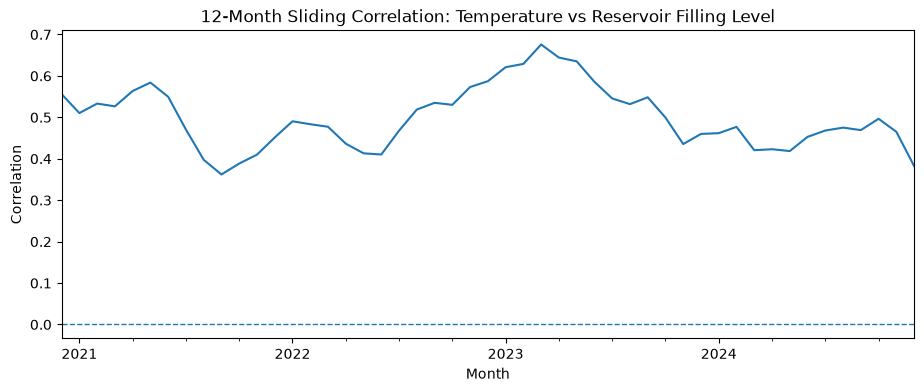

In [93]:
ax = corr_temperature[
    "correlation"
].plot(
    figsize=(11, 4),
    title=(
        "12-Month Sliding Correlation: "
        "Temperature vs Reservoir Filling Level"
    ),
)

ax.axhline(
    0,
    linestyle="--",
    linewidth=1,
)

ax.set_ylabel(
    "Correlation"
)

ax.set_xlabel(
    "Month"
)

#### Interpretation

The rolling correlation is positive during the first displayed periods, with values around 0.6. However, the purpose of the sliding-window approach is to inspect how this relationship changes over time rather than to summarise it using a single coefficient.

The following experiments therefore focus on lag, weather-variable choice and rolling-window length.

### 8.4 Effect of Weather Lag

Precipitation is compared with monthly changes in reservoir filling using lags from zero to six months and a 12-month rolling window.

Both the mean correlation and the mean absolute correlation are reported. The absolute measure is useful for identifying strong relationships regardless of whether their direction is positive or negative.

In [94]:
lag_results = []

for lag in range(0, 7):

    result = sliding_window_correlation(
        correlation_data,
        weather_property="total_precipitation",
        reservoir_property="fill_change",
        lag=lag,
        window=12,
    )

    lag_results.append(
        {
            "lag_months": lag,
            "mean_correlation": (
                result["correlation"].mean()
            ),
            "mean_absolute_correlation": (
                result["correlation"]
                .abs()
                .mean()
            ),
        }
    )

lag_comparison = pd.DataFrame(
    lag_results
)

display(lag_comparison)

,lag_months,mean_correlation,mean_absolute_correlation
0,0,0.119892,0.164188
1,1,-0.195684,0.213058
2,2,-0.334506,0.375038
3,3,-0.330964,0.330964
4,4,-0.184855,0.243603
5,5,-0.157409,0.336386
6,6,-0.171961,0.249376


#### Interpretation

The strongest relationship among the tested precipitation lags occurs at a **two-month lag**, with a mean correlation of approximately **-0.462** and a mean absolute correlation of approximately **0.467**.

The contemporaneous relationship is much weaker, with a mean absolute correlation of approximately **0.143**.

This suggests that precipitation may be more strongly associated with reservoir changes after a delay rather than within the same month. Possible mechanisms include delayed runoff, soil storage and snow accumulation, but the correlation analysis alone cannot determine the underlying cause.

### 8.5 Comparison of Weather Variables

Temperature, precipitation and snowfall are compared using the same settings: a one-month lag, a 12-month rolling window and monthly change in reservoir filling as the response variable.

Using identical settings makes the relative strength and direction of the three meteorological relationships easier to compare.

In [95]:
weather_properties = [
    "avg_temperature",
    "total_precipitation",
    "total_snowfall",
]

weather_results = []

for weather_property in weather_properties:

    result = sliding_window_correlation(
        correlation_data,
        weather_property=weather_property,
        reservoir_property="fill_change",
        lag=1,
        window=12,
    )

    weather_results.append(
        {
            "weather_property": weather_property,
            "mean_correlation": (
                result["correlation"].mean()
            ),
            "mean_absolute_correlation": (
                result["correlation"]
                .abs()
                .mean()
            ),
        }
    )

weather_comparison = pd.DataFrame(
    weather_results
).sort_values(
    "mean_absolute_correlation",
    ascending=False,
)

display(weather_comparison)

,weather_property,mean_correlation,mean_absolute_correlation
0,avg_temperature,0.473214,0.473214
2,total_snowfall,-0.424748,0.424748
1,total_precipitation,-0.195684,0.213058


#### Interpretation

With a one-month lag:

- **Temperature** has the strongest mean relationship, with a correlation of approximately **+0.441**.
- **Snowfall** shows a negative mean correlation of approximately **-0.400**.
- **Precipitation** shows a negative mean correlation of approximately **-0.357**.

Temperature therefore has the largest mean absolute correlation under these particular settings.

A possible interpretation is that warmer conditions may coincide with snowmelt and increased inflow, while snowfall can temporarily store water as snow rather than immediately contributing to reservoir inflow. These explanations are plausible hydrological interpretations, but the analysis establishes association rather than causality.

### 8.6 Effect of Rolling-Window Length

The rolling-window length is varied between 6 and 24 months while precipitation, a one-month lag and monthly filling change are kept constant.

Shorter windows respond more quickly to changing relationships, while longer windows produce smoother and more stable correlation estimates.

In [96]:
window_results = []

for window in [6, 12, 18, 24]:

    result = sliding_window_correlation(
        correlation_data,
        weather_property="total_precipitation",
        reservoir_property="fill_change",
        lag=1,
        window=window,
    )

    window_results.append(
        {
            "window_months": window,
            "mean_correlation": (
                result["correlation"].mean()
            ),
            "mean_absolute_correlation": (
                result["correlation"]
                .abs()
                .mean()
            ),
        }
    )

display(
    pd.DataFrame(window_results)
)

,window_months,mean_correlation,mean_absolute_correlation
0,6,-0.168085,0.462117
1,12,-0.195684,0.213058
2,18,-0.210530,0.210822
3,24,-0.214446,0.214446


#### Interpretation

The six-month window produces the largest mean absolute correlation, approximately **0.437**.

The corresponding values for 12, 18 and 24 months are approximately **0.357**, **0.360** and **0.362**, respectively.

This suggests that shorter windows capture stronger temporary variations in the precipitation-reservoir relationship. However, a six-month correlation is calculated from relatively few observations and is therefore more sensitive to individual months and statistical noise.

A 12-month window provides a reasonable compromise between responsiveness and stability and is therefore suitable as a default setting in the Streamlit application.

### 8.7 Findings

The sliding-window analysis confirms that relationships between meteorological conditions and reservoir filling are sensitive to the selected weather variable, lag and rolling-window length.

Using a one-month lag and a 12-month window, **temperature** shows the strongest average relationship with monthly reservoir changes, with a mean correlation of approximately **+0.44**. Snowfall and precipitation show negative relationships of approximately **−0.40** and **−0.36**, respectively.

The lag experiment shows that precipitation has its strongest tested relationship with reservoir changes at approximately a **two-month lag**, where the mean absolute correlation reaches about **0.47**. This is substantially stronger than the contemporaneous precipitation relationship and suggests that delayed weather effects may be relevant.

The rolling-window experiment also shows that the estimated relationship depends on the selected window length. A six-month window gives the strongest mean absolute correlation, but shorter windows are more sensitive to individual observations and temporary seasonal effects. Longer windows produce more stable but less responsive estimates.

These results support the inclusion of selectable weather variables, lag and rolling-window length in the Streamlit application. They also suggest that meteorological variables may provide useful information for reservoir forecasting.

However, all results should be interpreted as statistical associations rather than causal effects. Reservoir filling is influenced by several additional factors, including hydrology, electricity production, reservoir management and seasonal operating decisions.

## 9. Streamlit Structure and Design

Before refactoring the Streamlit application, the existing and new functionality was reorganised around the user's analytical workflow rather than around individual data sources.

The application is divided into three main functional groups:

1. **Explore** – geographical selection and descriptive data exploration.
2. **Analyse** – seasonal patterns, anomaly detection and relationships between datasets.
3. **Predict** – forecasting of future reservoir filling levels.

This structure creates a natural user journey from understanding the current and historical data to analysing relationships and finally producing forecasts.

### 9.1 Navigation Structure

The final application structure is:

```text
IND320 Energy Dashboard
│
├── Home
│
├── EXPLORE
│   │
│   ├── Map & Data Overview
│   │   ├── Interactive GeoJSON map
│   │   ├── Area type: Price areas / Water regions / Norway
│   │   ├── Area selection
│   │   ├── Time-period selection
│   │   ├── Reservoir indicators
│   │   └── Weather overlays
│   │
│   └── Energy & Markets
│       ├── Cross-border electricity flows
│       └── EUR/NOK and USD/NOK exchange rates
│
├── ANALYSE
│   │
│   ├── Seasonal Patterns
│   │   ├── STL decomposition
│   │   └── Spectrogram
│   │
│   ├── Weather & Anomalies
│   │   ├── SATV / SPC
│   │   └── Local Outlier Factor
│   │
│   └── Weather–Reservoir Correlation
│       ├── Weather property
│       ├── Reservoir property
│       ├── Lag
│       └── Rolling-window length
│
├── PREDICT
│   │
│   └── Reservoir Forecast
│       ├── Training period
│       ├── Forecast horizon
│       ├── SNARIMAX parameters
│       ├── Exogenous variables
│       └── Animated Plotly forecast
│
└── INFORMATION
    │
    └── About

### 9.2 Shared and Local Controls

The selected geographical area is treated as shared application state and is stored using `st.session_state`.

The following selections can be shared between relevant pages:

- area type
- selected area number
- selected map time period

This allows a geographical selection made on the **"Map & Data Overview"** page to be reused in later analysis and forecasting pages.

Controls that only affect a specific analysis remain local to that page. These include:

- SATV/SPC parameters
- LOF parameters
- weather-property selection
- correlation lag and rolling-window length
- SNARIMAX parameters
- exogenous-variable selection
- forecast horizon

Separating shared and local controls avoids unnecessary repetition while preventing unrelated page settings from affecting each other.

### 9.3 Design Rationale

The application is organised around the workflow:

**Explore -> Analyse -> Predict**

The **Explore** section provides the geographical and descriptive starting point. The "Map & Data Overview"-page combines functionality that was previously separated between reservoir-data and reservoir-plot pages, reducing duplication and making the selected geographical area the central context for the rest of the application.

The **Analyse** section contains tools for investigating historical patterns, anomalies and weather-reservoir relationships. This separates descriptive analysis from forecasting while allowing the selected geographical context to be reused.

The **Predict** section contains the reservoir forecasting interface, where users can configure the training history, forecast horizon, SNARIMAX parameters and exogenous variables.

Interactive visualisations are implemented using Plotly throughout the redesigned pages. This replaces the static plots from earlier versions of the application and allows users to inspect values and time periods interactively.

Overall, the structure is intended to make the application behave as one coherent analytical dashboard rather than as a collection of separate compulsory-assignment tasks.

## 10. Streamlit Implementation

The analyses developed in the previous sections were integrated into the existing Streamlit application. The implementation focuses on interactive exploration, consistent navigation and reuse of shared project modules.

The redesigned application follows the workflow:

Explore -> Analyse -> Predict

Rather than reproducing the complete Streamlit source code in the notebook, this section documents the main functionality implemented on each page. The complete application code is available in the GitHub repository.

### 10.1 Navigation and Application Structure

The application navigation is implemented using `st.navigation()` and `st.Page()`. Pages are grouped according to their analytical purpose:

- **Explore:** Map & Data Overview and Energy & Markets
- **Analyse:** Seasonal Patterns, Weather & Anomalies and Weather-Reservoir Correlation
- **Predict:** Reservoir Forecast
- **Information:** About

This replaces the flatter page structure used in earlier compulsory assignments and creates a clearer workflow for the user.

Relevant geographical selections are stored in `st.session_state`, allowing the selected area and map time period to be reused by later parts of the dashboard.

### 10.2 Map & Data Overview

The "Map & Data Overview"-page acts as the main geographical entry point to the dashboard.

An interactive Plotly GeoJSON choropleth allows the user to switch between:

- electricity price areas
- water regions
- Norway as a whole

The areas can be coloured by reservoir filling level, stored energy, capacity, temperature, precipitation or snowfall.

Reservoir metrics use the latest available observation within the selected period. Weather overlays are calculated from ERA5 observations over the selected time interval.

To reduce loading time and API usage, weather-map calculations use three reproducibly sampled geographical locations per region.

Weather overlays are limited to a maximum period of 24 months to avoid excessively large Open-Meteo requests. The selectable weather period is also restricted to months for which ERA5 observations are available.

Clicking an area on the map updates the selected area in `st.session_state`. The page also displays key reservoir indicators and an interactive time-series plot for the selected region.

### 10.3 Energy & Markets

The "Energy & Markets"-page combines two external data sources.

ENTSO-E physical cross-border electricity-flow data are retrieved from the project's MongoDB dataset. Users can select an electricity connection, year and months and inspect imports and exports using interactive Plotly visualisations. High-frequency physical-flow observations are aggregated to daily mean values for the time-series visualisation, making longer periods easier to interpret.

The page also retrieves EUR/NOK and USD/NOK exchange rates from Norges Bank and displays their development for the selected year.

Combining the two datasets on one page reduces the number of separate pages while grouping market-related information together.

### 10.4 Seasonal Patterns

The "Seasonal Patterns"-page contains two methods for analysing historical reservoir behaviour:

- STL decomposition
- spectrogram analysis

The previous static Matplotlib figures were replaced with interactive Plotly visualisations.

Users can adjust the STL seasonal and trend smoothing parameters and enable robust fitting. For the spectrogram, users can control the window length and overlap.

The selected geographical area determines which reservoir filling-level series is analysed.

### 10.5 Weather & Anomalies

The "Weather & Anomalies"-page extends the anomaly-detection functionality from the previous compulsory assignment.

Users can select between:

- temperature
- precipitation
- snowfall

The selected weather property can then be analysed using both SATV/SPC and Local Outlier Factor.

Temperature is used as the default meteorological variable. The anomaly plots were converted from static Matplotlib figures to interactive Plotly visualisations.

Users can also modify relevant method parameters, including the DCT cut-off, SPC boundary width, LOF contamination and number of neighbours.

### 10.6 Weather-Reservoir Correlation

A dedicated Streamlit page was created for the sliding-window correlation analysis developed in Section 8.

The user can interactively select:

- meteorological variable
- reservoir filling level or monthly filling change
- weather lag
- rolling-window length
- analysis period

ERA5 weather observations are retrieved at daily resolution because the correlation analysis is subsequently aggregated to monthly values. Five reproducibly sampled geographical locations are used, and the coordinates are grouped into a single Open-Meteo request to reduce API usage.

The page calculates the rolling correlation dynamically and displays the result using Plotly.

Summary indicators show the mean correlation, mean absolute correlation and strongest observed rolling correlation. The page also explicitly notes that the results represent statistical associations rather than causal effects.

### 10.7 Reservoir Forecast

The "Reservoir Forecast"-page provides an interactive interface for the River SNARIMAX model.

Users can configure:

- training-history length
- forecast horizon
- non-seasonal SNARIMAX parameters
- seasonal SNARIMAX parameters
- weather variables
- EUR/NOK and USD/NOK

Historical weather observations used for forecasting are retrieved at daily resolution and subsequently aggregated to monthly values. Multiple sampled geographical locations are requested together in a single Open-Meteo call to reduce API usage.

The default settings correspond to the strongest configuration identified in the notebook experiments.

When possible, the forecast training period can be synchronised with the end month selected on the Map & Data Overview page.

Future weather values are approximated using historical calendar-month averages, while future exchange rates use the latest observed value. These values are presented as assumptions rather than independent forecasts.

Both the unconstrained SNARIMAX predictions and the physically constrained reservoir forecasts are retained. Predictions displayed to the user are clipped to the valid filling-level interval `[0, 1]`.

The page includes both a standard interactive forecast plot and a Plotly animation showing how the forecast horizon develops step by step.

### 10.8 Performance, Caching and Error Handling

Several measures were implemented to improve application performance and robustness.

Repeated API calls and geographical calculations use Streamlit caching where appropriate. Loading indicators are displayed while weather data and forecasts are being prepared.

The ERA5 availability date is checked before weather requests are made, preventing requests for observations that have not yet been published.

External API and database calls also include error handling so that failures produce informative Streamlit messages rather than causing the entire application to fail without explanation.

Representative geographical sampling and batched Open-Meteo requests are used to reduce both the amount of external data retrieved and the number of API calls. Weather-map requests are additionally limited to a maximum period of 24 months to avoid excessively large requests and long loading times.

API rate-limit errors, unavailable data and connection failures are caught and presented as informative Streamlit messages rather than raw application errors.

Together, caching, loading indicators and error handling satisfy the additional usability and robustness functionality requested in the assignment.

## 11. AI Usage

Generative AI was used as a supporting tool during the development of this compulsory assignment. ChatGPT was primarily used for discussing implementation approaches, debugging errors, improving code structure, suggesting Streamlit layouts, and explaining technical concepts.

AI support was used in particular for:

- Structuring the notebook and Streamlit application
- Help with implementing and debugging the Norges Bank API integration
- Investigating timezone handling across NVE, ENTSO-E, Open-Meteo and Norges Bank data
- Help with developing and testing the River SNARIMAX forecasting workflow
- Help with implementing sliding-window correlation analysis
- Refactoring static Matplotlib visualisations to interactive Plotly figures
- Help with developing the interactive GeoJSON map and Streamlit session-state logic
- Improving error handling, caching and loading indicators
- Reviewing code and interpreting errors encountered during implementation.
- Spelling correction and better sentence structure

All generated suggestions were carefully reviewed, adapted and tested before being included in the project. The final implementation decisions, parameter choices and interpretations were based on the assignment requirements and the observed behaviour of the data and application.

AI was therefore used mainly as a programming and problem-solving assistant rather than as a source of project data or empirical results.

## 12. Work Log

The work on Compulsory Assignment 4 started by extending the existing project from the previous compulsory assignments. The first step was to create a separate feature branch and establish the new notebook structure.

I first implemented a function for downloading EUR/NOK and USD/NOK exchange rates from the Norges Bank API. The returned observations were cleaned and converted into a format suitable for later monthly aggregation. I then investigated timestamp and timezone handling across Magasinstatistikk, ENTSO-E, Open-Meteo and Norges Bank. ENTSO-E and Open-Meteo timestamps were standardised as UTC, while the weekly NVE and daily Norges Bank observations were treated as calendar-based observations.

The next major part was reservoir forecasting. Reservoir filling, ERA5 weather variables and exchange rates were aggregated to monthly resolution and joined into a common dataset. A River SNARIMAX model was implemented with configurable model parameters, training history, forecast horizon and exogenous variables. Several model configurations were compared using MAE and RMSE. The best-performing tested configuration used seasonal SNARIMAX with both weather and currency variables. A separate future-forecasting function was then implemented. Because future weather and exchange rates are not known, monthly historical weather averages and the latest observed exchange rates were used as transparent assumptions. Raw forecasts outside the physical reservoir range of 0-1 were retained but clipped for display.

I also implemented a sliding-window correlation analysis between meteorological variables and reservoir filling. Different weather variables, lags and rolling-window lengths were tested. The results showed that the relationship between weather and reservoir conditions changes over time and depends considerably on the chosen lag and window length.

The Streamlit application was then substantially reorganised into the workflow: **Explore -> Analyse -> Predict**. The previous reservoir data and plotting pages were combined into an interactive "Map & Data Overview"-page with GeoJSON polygons, selectable geographical areas, weather overlays and shared session-state selections. Existing static visualisations were converted to Plotly. "The Weather & Anomalies"-page was expanded so that SATV/SPC and LOF can be applied to temperature, precipitation and snowfall.

Finally, new Streamlit pages were added for sliding-window correlation and River SNARIMAX forecasting. The forecast page includes selectable parameters, exogenous variables, synchronisation with the map timeframe and an animated Plotly forecast. Caching, loading indicators and error handling were also added to improve application performance and usability. For the bonus content, I implemented both the waiting time and error handling tasks by adding caching, loading indicators, API availability checks and informative error messages.